**CURSO**: *Machine Learning* en Geociencias<br />
**Profesor**: Edier Aristizábal (evaristizabalg@unal.edu.co) <br />
**Créditos**: El contenido de este notebook proviene de varias fuentes, como [MyNotes](https://peterroelants.github.io/posts/linear-regression-four-ways/#4.-Markov-Chain-Monte-Carlo-parameter-estimation). Se ha hecho todo lo posible por identificar a los titulares de los derechos de los materiales usados en este notebook. El autor se disculpa por cualquier omisión involuntaria y con gusto agregará el reconocimiento en futuras ediciones.


La regresión lineal es uno de los modelos de aprendizaje automático más simples que existen. Según algunos, ni siquiera debería clasificarse como "aprendizaje automático" porque es demasiado simple. Sea cual sea tu opinión, creo que su simplicidad lo convierte en un excelente trampolín hacia modelos y algoritmos más complejos. Inspirándonos en la clásica pizza, exploraremos el modelo de regresión lineal con cuatro diferentes sabores para estimar sus parámetros. Espero que esto ayude a construir nuestra comprensión de este modelo básico

Para el detalle teórico de cada método ir al [link](https://peterroelants.github.io/posts/linear-regression-four-ways/#4.-Markov-Chain-Monte-Carlo-parameter-estimation). 

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm


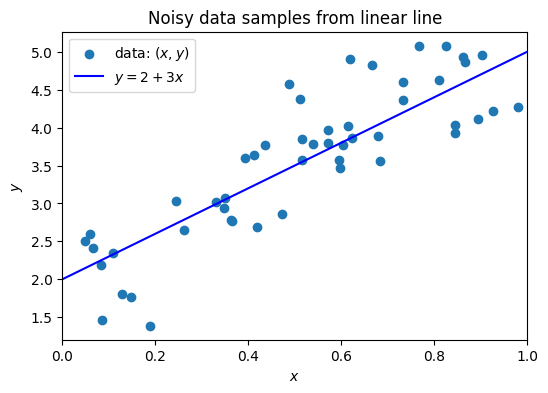

In [5]:
# Define the data
np.random.seed(4)
# Generate random data
n = 50 # Número de muestras
# Underlying linear relation
m = 3  # slope
b = 2  # bias
# Noise
e_std = 0.5  # Desviación estándar del ruido
err = e_std * np.random.randn(n)  # Noise
# Features and output
x = np.random.uniform(0, 1, n)  # Independent variable x
y = x * m + b + err  # Dependent variable
# Agregar a X una columna de unos para ajustar con métodos vectorizados
#  como MCO y descenso por gradiente
X = np.vstack((np.ones_like(x), x)).T

# Show data
plt.figure(figsize=(6, 4))
plt.scatter(x, y, label='data: $(x,y)$')
plt.plot(
    [0, 1], [b, m+b], 'b-', 
    label=f'$y = {b:.0f} + {m:.0f} x$')
plt.xlim((0, 1))
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title('Noisy data samples from linear line')
plt.legend()
plt.show()

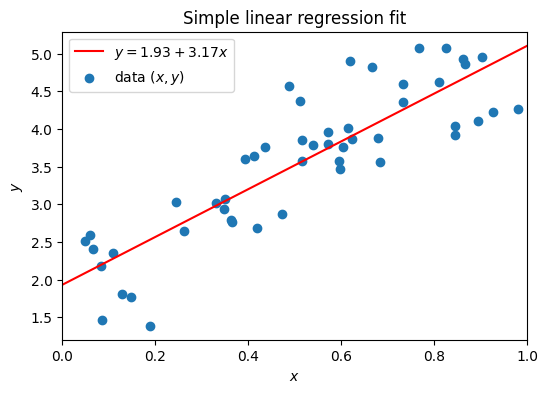

In [7]:
# Simple linear regression
# Compute mean
x_mean = np.mean(x)
y_mean = np.mean(y)

# Compute parameters according to simple linear regression
theta_1 = (
    (x-x_mean) * (y-y_mean)).sum() / ((x-x_mean)**2).sum()
theta_0 = y_mean - theta_1 * x_mean

# Function representing fitted line
f = lambda x: theta_0 + theta_1 * x

# Show simple linear regression fitted line
plt.figure(figsize=(6, 4))
plt.plot(
    [0, 1], [f(0), f(1)], 'r-', 
    label=f'$y = {theta_0:.2f} + {theta_1:.2f} x$')
plt.scatter(x, y, label='data $(x,y)$')
plt.legend()
plt.title('Simple linear regression fit')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.xlim((0, 1))
plt.show()

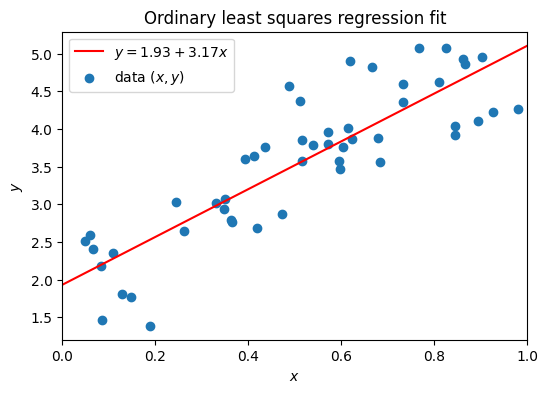

In [8]:
# Ordinary least squares
# Fit parameters with OLS
Theta = np.linalg.inv(X.T @ X) @ X.T @ y

# Function representing fitted line
f = lambda x: Theta[0] + Theta[1] * x

# Show OLS fitted line
plt.figure(figsize=(6, 4))
plt.plot(
    [0, 1], [f(0), f(1)], 'r-', 
    label=f'$y = {Theta[0]:.2f} + {Theta[1]:.2f} x$')
plt.scatter(x, y, label='data $(x,y)$')
plt.legend()
plt.title('Ordinary least squares regression fit')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.xlim((0, 1))
plt.show()

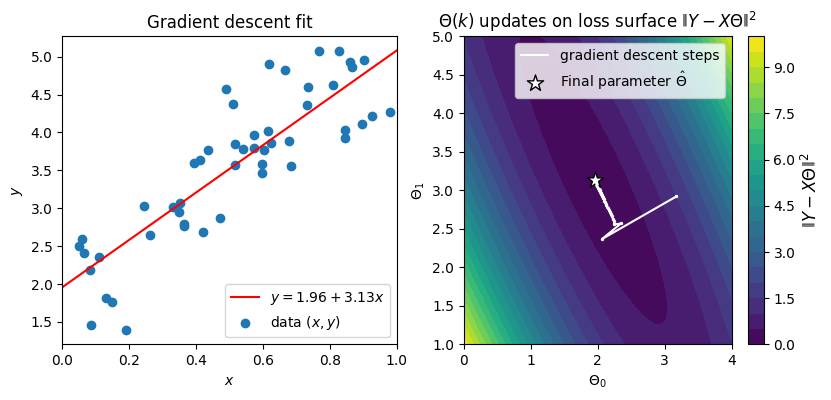

In [11]:
# Gradient descent update
def update(Theta, X, y, learning_rate):
    """Update the parameters with one iteration."""
    grad = - 2 * X.T @ (y - (X @ Theta))  # Compute gradient
    Theta -= grad * learning_rate  # Update paramters
    return Theta

# Implementation of gradient descent
# Random initial parameters
np.random.seed(13)
Theta = np.random.randn(2)
learning_rate = 0.01  # Learning rate
losses = []  # Guardará la pérdida (costo) de cada iteración
params = []  # Guardará los parámetros Theta de cada iteración

# Run gradient descent for a number of steps
for i in range(50):
    Theta = update(Theta, X, y, learning_rate)
    # Store iterations for visualisation
    losses.append(np.mean((y-(X@Theta))**2))
    params.append(Theta.copy())

# Function representing fitted line
f = lambda x: Theta[0] + Theta[1] * x

# Show fitted line
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 4))
ax1.plot(
    [0, 1], [f(0), f(1)], 'r-', 
    label=f'$y = {Theta[0]:.2f} + {Theta[1]:.2f} x$')
ax1.scatter(x, y, label='data $(x, y)$')
ax1.legend()
ax1.set_title('Gradient descent fit')
ax1.set_xlabel('$x$')
ax1.set_ylabel('$y$')
ax1.set_xlim((0, 1))
# Show loss surface
nb_of_ws = 50 # calcular la pérdida nb_of_ws veces en cada dimensión
wsa = np.linspace(0, 4, num=nb_of_ws) # theta_0
wsb = np.linspace(1, 5, num=nb_of_ws) # theta_1
ws_x, ws_y = np.meshgrid(wsa, wsb) # generate grid
loss_ws = np.zeros((nb_of_ws, nb_of_ws)) # initialize loss matrix
# Llenar la matriz de pérdida para cada combinación de pesos
for i in range(nb_of_ws):
    for j in range(nb_of_ws):
        theta = np.asarray([ws_x[i,j], ws_y[i,j]])
        loss_ws[i,j] = np.mean((y - (X @ theta))**2)
# Plot the loss function surface
cont = ax2.contourf(ws_x, ws_y, loss_ws, 20, cmap=cm.viridis)
# Plot the parameter updates
theta_prev = None
has_label = False
params_arr = np.vstack(params)
# Graficar los valores parámetro-pérdida que representan la actualización
ax2.scatter(params_arr[:,0], params_arr[:,1], color='w', s=2)
ax2.plot(params_arr[:,0], params_arr[:,1], 'w-', label='gradient descent steps')
ax2.scatter(
    [Theta[0]], [Theta[1]], label='Final parameter $\\hat{\\Theta}$',
    color='w', marker='*', s=150, edgecolors='k')
cbar = plt.colorbar(cont)
cbar.set_label('X+Y')
cbar.ax.set_ylabel(
    '$\\left\\Vert Y-X\\Theta \\right\\Vert^2$', fontsize=12)
ax2.set_title((
    '$\\Theta(k)$ updates on loss surface '
    '$\\left\\Vert Y-X\\Theta \\right\\Vert^2$'))
ax2.set_xlabel('$\\Theta_0$')
ax2.set_ylabel('$\\Theta_1$')
ax2.legend()
plt.show()

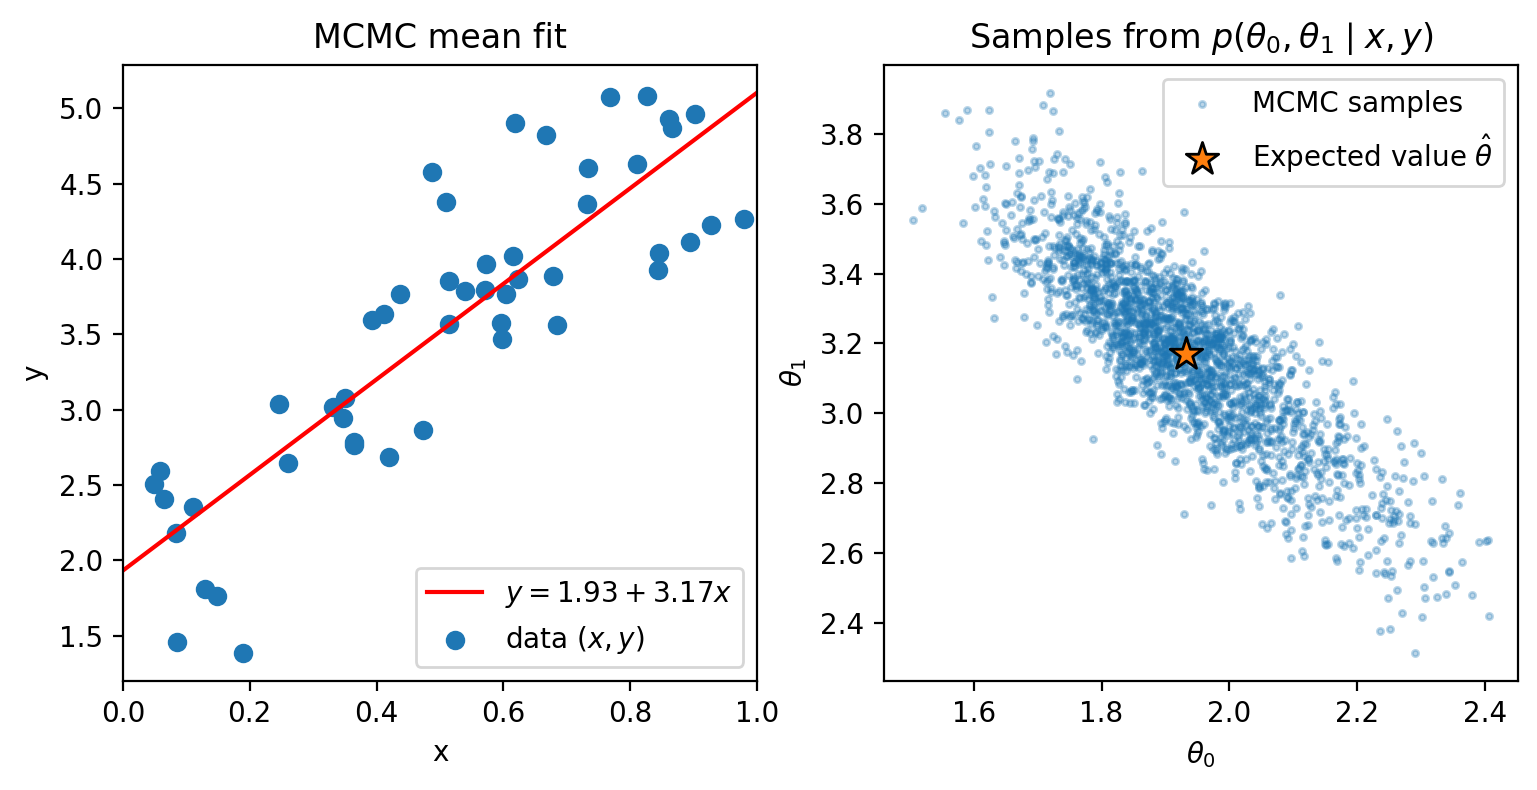

In [16]:
def metropolis_hastings_step(y, x, theta_0, theta_1, sigma):
    """Single step of the Metropolis-Hastings algorithm."""
    # Run until new proposed sample has been accepted
    while True:
        theta_0_p = theta_0 + np.random.randn(1) * 0.1
        theta_1_p = theta_1 + np.random.randn(1) * 0.1
        sigma_p = sigma + np.random.randn(1) * 0.1
        log_ratio = (
            log_likelihood(y, x, theta_0_p, theta_1_p, sigma_p) - 
            log_likelihood(y, x, theta_0, theta_1, sigma))
        if log_ratio >= np.e:
            # Ratio >= 1: accept proposal
            return theta_0_p, theta_1_p, sigma_p
        elif np.log(np.random.uniform()) < log_ratio:
            # Ratio < 1: check with probability == ratio
            return theta_0_p, theta_1_p, sigma_p
        

def log_likelihood(y, x, theta_0, theta_1, sigma):
    """Log-likelihood function."""
    sigma_sq = sigma**2
    # Sum of squared errors
    sse = sum((y - (theta_0+theta_1*x)) ** 2)
    return - len(y) * np.log(np.sqrt(2*np.pi*sigma_sq)) \
        - (sse/(2*sigma_sq))

# Implementation of metropolis-Hasting MCMC
np.random.seed(1)

# Initial parameters
theta_0 = 1.
theta_1 = 1.
sigma = 1.

# Run Metropolis-Hastings MCMC
samples = []  # Lista de todas las muestras
for _ in range(3000):
    # Generate new parameter proposals
    theta_0, theta_1, sigma = metropolis_hastings_step(
        y, x, theta_0, theta_1, sigma)
    samples.append((theta_0, theta_1, sigma))


th_0_samples, th_1_samples, sigma_samples = zip(*samples)
# Calcular el valor esperado de las últimas muestras
# Las primeras 1000 muestras se ignoran porque el MCMC no ha
#  yet converged
theta_0 = np.mean(th_0_samples[1000:])
theta_1 = np.mean(th_1_samples[1000:])

# Function representing fitted line
f = lambda x: theta_0 + theta_1 * x

# Show fitted line
%config InlineBackend.figure_formats = ['retina']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9,4), dpi=100)
ax1.plot(
    [0, 1], [f(0), f(1)], 'r-', 
    label=f'$y = {theta_0:.2f} + {theta_1:.2f} x$')
ax1.scatter(x, y, label='data $(x,y)$')
ax1.legend()
ax1.set_title('MCMC mean fit')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_xlim((0, 1))

ax2.scatter(
    th_0_samples[1000:], th_1_samples[1000:], 
    alpha=0.3, s=5, label='MCMC samples')
ax2.scatter(
    [theta_0], [theta_1], label='Expected value $\\hat{\\theta}$',
    s=150, marker='*', edgecolors='k')
ax2.set_title('Samples from $p(\\theta_0, \\theta_1 \\mid x,y)$')
ax2.set_xlabel('$\\theta_0$')
ax2.set_ylabel('$\\theta_1$')
ax2.legend()
plt.show()